# Evaluación Grupal · EduAnalytics (CRISP-DM, Fases 1–4)
### Proyecto: Análisis de Patrones de Uso de IA Generativa y Riesgo de Burnout Estudiantil

---

### Datos Generales del Proyecto
* **Institución Educativa:** Universidad Privada Franz Tamayo (UNIFRANZ)
* **Facultad / Carrera:** Ingeniería de Sistemas
* **Materia:** Minería de Datos
* **Integrantes del Grupo:**
  1. **Milenka Melody Chuquimia Osco**
  2. **Edson Teddy Tito Chuquimia**
  3. **Carlos Daniel Valverde Mendoza**
  4. **Alvaro Luis Carlos del Carpio Blanco**
  5. **Marcelo Josue Escobar Chipana**

---

### Propósito y Alcance del Cuaderno
Este notebook responde y documenta de forma integral y paso a paso las **10 preguntas de la evaluación grupal**, cubriendo las fases 1 a 4 del estándar **CRISP-DM** (Entendimiento del Negocio, Comprensión de los Datos, Preparación de los Datos y Modelado).

**Características de esta versión autónoma:**
* **Autocontenido:** No requiere de módulos externos, scripts auxiliares ni archivos precalculados.
* **Recalculado en vivo:** Realiza la limpieza, el particionado estratificado exacto (70% Train, 15% Validation, 15% Test), el entrenamiento de modelos de clase (Regresión Logística y Árbol de Decisión), el cálculo de métricas y la generación de gráficos en tiempo real.
* **Única dependencia:** El archivo de datos `ai_student_impact_dataset (1).csv`. El código busca el archivo en la misma carpeta del notebook o en la carpeta `dataset/`.
* **Marco de análisis:** Clasificación multiclase retrospectiva sobre registros completos. La etiqueta `Burnout_Risk_Level` no constituye un diagnóstico clínico y el análisis describe asociaciones estadísticas dentro de la muestra, sin inferir causalidad ni detección anticipada.


In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown

# Configuración de advertencias y visualización
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

SEED = 42
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

FUENTE = 'Fuente: Kaggle «AI Usage & Student Academic Performance Analysis» v1 (CC0); cálculo propio.'

# Definición centralizada de variables del proyecto
CLASES = ['Low', 'Medium', 'High']
OBJETIVO = 'Burnout_Risk_Level'

NUMERICAS = [
    'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Tool_Diversity', 'Traditional_Study_Hours',
    'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score'
]

CATEGORICAS = [
    'Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Institutional_Policy'
]

BOOLEANAS = ['Paid_Subscription']

PREDICTORES = [
    'Major_Category', 'Year_of_Study', 'Pre_Semester_GPA', 'Weekly_GenAI_Hours',
    'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Paid_Subscription',
    'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Institutional_Policy',
    'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score'
]

TRAZABILIDAD = ['_row_id', 'Student_ID']

def crear_preprocesador(tipo_modelo):
    '''Construye un ColumnTransformer desacoplado y sin fuga de información.'''
    if tipo_modelo not in {'logistica', 'arbol'}:
        raise ValueError("tipo_modelo debe ser 'logistica' o 'arbol'.")
    
    # La regresión logística requiere estandarización; los árboles de decisión usan las escalas originales
    numerico = Pipeline([('escalado', StandardScaler())]) if tipo_modelo == 'logistica' else 'passthrough'
    
    columnas = ColumnTransformer([
        ('numericas', numerico, NUMERICAS),
        ('categoricas', OneHotEncoder(drop=None, handle_unknown='ignore', sparse_output=False), CATEGORICAS),
        ('booleanas', FunctionTransformer(np.asarray, kw_args={'dtype': np.float64}, feature_names_out='one-to-one'), BOOLEANAS),
    ], remainder='drop', sparse_threshold=0)
    
    return Pipeline([('columnas', columnas)])

# Búsqueda dinámica del archivo CSV
posibles_rutas = [
    Path('ai_student_impact_dataset (1).csv'),
    Path('./ai_student_impact_dataset (1).csv'),
    Path('../dataset/ai_student_impact_dataset (1).csv'),
    Path('dataset/ai_student_impact_dataset (1).csv'),
    Path('../../dataset/ai_student_impact_dataset (1).csv')
]

RUTA_CSV = next((p for p in posibles_rutas if p.is_file()), None)
if RUTA_CSV is None:
    raise FileNotFoundError("No se encontró el archivo 'ai_student_impact_dataset (1).csv'. Asegúrese de colocarlo en la misma carpeta del notebook o en dataset/.")

print("Entorno inicializado correctamente:")
print("• Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("• Archivo de datos localizado:", RUTA_CSV.resolve())


Entorno inicializado correctamente:
• Python: 3.10.6 | pandas: 2.3.3 | scikit-learn: 1.7.2
• Archivo de datos localizado: C:\md-edu-analytics\ENTREGABLES\ai_student_impact_dataset (1).csv


## 1 · Problema, decisión y criterio de éxito de negocio (Pregunta 1)

### Contexto del Problema
Saber que un estudiante universitario utiliza Inteligencia Artificial Generativa no indica *cómo* la emplea, con qué frecuencia ni cómo ese uso interactúa con sus hábitos de estudio, su rendimiento académico y su bienestar emocional. El dataset recopila registros de estudiantes con métricas de uso de IA, hábitos tradicionales, ansiedad, retención de habilidades y la etiqueta de riesgo de agotamiento académico `Burnout_Risk_Level` (`Low`, `Medium`, `High`).

### Decisión que apoya el análisis
Proveer evidencia cuantitativa para diseñar **materiales de orientación sobre el uso responsable y eficiente de herramientas de IA**, así como definir criterios técnicos para **priorizar programas de acompañamiento y tutoría académica** dirigidos a los perfiles estudiantiles con mayor vulnerabilidad (`High`).
* **Usuarios potenciales:** Coordinaciones de carrera, docentes, tutores académicos y equipos de bienestar estudiantil.
* **Afectados:** Los estudiantes universitarios representados en la cohorte analizada.

### Conexión análisis–necesidad
1. **Fase Exploratoria:** Identificar patrones de comportamiento y hábitos marcadamente asociados con el riesgo alto (`High`).
2. **Fase de Modelado:** Desarrollar y evaluar modelos predictivos multiclase que clasifiquen de forma interpretable y reproducible las tres categorías de riesgo.

### Criterios de Éxito
* **De Negocio:** Establecer una línea base descriptiva transparente de la proporción de estudiantes en riesgo alto (`KPI = % High`), que sirva de referencia para futuras evaluaciones tras aplicar programas de intervención.
* **Técnico:** Desarrollar un modelo de aprendizaje automático que supere significativamente la línea base ingenua (*Dummy Classifier*) en la métrica **Macro F1**, evaluado estrictamente sobre un conjunto de prueba independiente.

> **Alcance y límites:** Clasificación retrospectiva basada en datos observacionales. La condición `High` refleja la etiqueta asignada en el dataset, no un diagnóstico clínico profesional. No se afirma causalidad ni capacidad de detección anticipada en tiempo real.


## 2 · Métrica principal y su cálculo (Pregunta 2)

Se establecen dos métricas complementarias con propósitos claramente diferenciados:

| Métrica | Ámbito | Tipo | Fórmula | Unidad / Escala |
| :--- | :--- | :--- | :--- | :--- |
| **KPI: % de registros `High`** | Negocio | Descriptiva de etiquetas | `KPI = (# registros High / # registros totales) × 100` | % (0 a 100) |
| **Macro F1 en prueba** | Técnico | Desempeño predictivo | Promedio no ponderado de F1 (`Low`, `Medium`, `High`) | Adimensional (0 a 1) |



In [2]:
# Carga del conjunto de datos y cálculo del KPI de negocio
df = pd.read_csv(RUTA_CSV, sep=';', encoding='utf-8-sig')

n_total = len(df)
n_high = int((df['Burnout_Risk_Level'] == 'High').sum())
kpi = (n_high / n_total) * 100

print(f"KPI de Negocio = {n_high:,} High / {n_total:,} registros × 100 = {kpi:.3f} %".replace(',', '.'))
assert (n_high, n_total) == (12487, 50000), "Error de verificación: los registros no coinciden con la línea base oficial."
print("Verificación exitosa: coincide exactamente con la línea base documentada (12.487 / 50.000 = 24,974 %).")

# Distribución completa de la variable objetivo
dist_objetivo = df['Burnout_Risk_Level'].value_counts().reindex(CLASES).to_frame('Registros')
dist_objetivo['% del total'] = (100 * dist_objetivo['Registros'] / n_total).round(3)
display(dist_objetivo)


KPI de Negocio = 12.487 High / 50.000 registros × 100 = 24.974 %
Verificación exitosa: coincide exactamente con la línea base documentada (12.487 / 50.000 = 24,974 %).


,Registros,% del total
Burnout_Risk_Level,,
Low,16369,32.738
Medium,21144,42.288
High,12487,24.974


**Acción concreta para mejorar la métrica (a futuro):**
* **Para el KPI de negocio:** Implementar talleres de gestión del tiempo y uso pedagógico de IA dirigidos prioritariamente a estudiantes con alto uso intensivo (identificados en la Sección 5). Posteriormente, medir una nueva cohorte bajo las mismas definiciones para contrastar si la tasa del 24,974 % disminuye.
* **Para el desempeño del modelo:** En la etapa de modelado, explorar en validación técnicas de ajuste de umbrales o ponderación de clases (`class_weight='balanced'`) para incrementar el *recall* de la clase `High` (ver Sección 9).


## 3 · Unidad de análisis, procedencia y dimensiones (Pregunta 3)

### Descripción de la Muestra y Dimensiones
* **Unidad de análisis:** Un estudiante universitario individual, identificado unívocamente por su `Student_ID` y caracterizado por su perfil académico, hábitos de estudio y nivel de riesgo.
* **Procedencia:** Repositorio público de Kaggle: *«AI Usage & Student Academic Performance Analysis»*, publicado por el usuario `ranaghulamnabi` (Versión 1, Licencia pública CC0 - Dominio Público).
* **Dimensiones brutas y procesadas:** 50.000 filas y 16 columnas. No se aplicó ningún filtrado ni exclusión de filas, conservando la integridad de los 50.000 estudiantes originales.


In [3]:
print("Resumen de procedencia y dimensiones:")
print(f"• Registros totales: {df.shape[0]:,} | Variables: {df.shape[1]}".replace(',', '.'))
print(f"• Identificadores únicos de estudiante: {df['Student_ID'].nunique():,} (sin duplicados)".replace(',', '.'))
print(f"• Filtros aplicados: Ninguno → Registros analizados: {len(df):,}".replace(',', '.'))

# Inspección de variables, tipos de datos y valores de ejemplo
tabla_variables = pd.DataFrame({
    'Tipo de dato': df.dtypes.astype(str),
    'Valores únicos': df.nunique(),
    'Ejemplo (Fila 0)': df.iloc[0]
})
display(tabla_variables)


Resumen de procedencia y dimensiones:
• Registros totales: 50.000 | Variables: 16
• Identificadores únicos de estudiante: 50.000 (sin duplicados)
• Filtros aplicados: Ninguno → Registros analizados: 50.000


,Tipo de dato,Valores únicos,Ejemplo (Fila 0)
Student_ID,int64,50000,100001
Major_Category,object,5,Humanities
Year_of_Study,object,5,Senior
Pre_Semester_GPA,float64,2389,2.418
Weekly_GenAI_Hours,float64,3566,23.31
Primary_Use_Case,object,5,Copywriting/Drafting
Prompt_Engineering_Skill,object,3,Beginner
Tool_Diversity,int64,5,1
Paid_Subscription,bool,2,True
Traditional_Study_Hours,float64,2516,8.13


> **Límites de procedencia:** Si bien la licencia y la estructura del dataset están verificadas, no se cuenta con auditoría independiente sobre el método de recolección de campo, el posible origen sintético de las observaciones ni la fórmula exacta mediante la cual se etiquetó `Burnout_Risk_Level`. UNIFRANZ corresponde a la institución académica de los autores de este informe, no al origen de recolección de los datos.


## 4 · Calidad de los datos y preparación (Pregunta 4)

Antes del modelado se ejecutó una batería completa de controles de calidad de datos que verificó la ausencia de anomalías estructurales:
1. **Valores nulos:** 0 celdas faltantes en todas las columnas.
2. **Duplicados:** 0 filas duplicadas y 50.000 identificadores `Student_ID` estrictamente únicos.
3. **Variantes textuales:** Las variables categóricas no presentan espacios residuales ni inconsistencias de mayúsculas/minúsculas.
4. **Rangos plausibles:** Todas las variables numéricas se encuentran dentro de límites lógicos (GPA entre 0 y 4, escalas Likert de 1 a 10, horas semanales de 0 a 168).
5. **Valores atípicos (IQR):** Se detectan 3.269 registros con valores extremos (principalmente en `Weekly_GenAI_Hours`), los cuales **se conservan íntegramente** dado que representan estudiantes con uso intensivo legítimo y son altamente informativos para predecir el riesgo alto.


In [4]:
# Verificación de integridad de calidad en código
calidad = {
    'Valores faltantes (nulos totales)': int(df.isna().sum().sum()),
    'Columnas con datos faltantes': [c for c in df.columns if df[c].isna().any()] or 'Ninguna',
    'Cadenas vacías o con solo espacios': int(sum(df[c].astype(str).str.strip().eq('').sum() for c in df.select_dtypes(['object']).columns)),
    'Filas duplicadas': int(df.duplicated().sum()),
    'Student_ID duplicados': int(df['Student_ID'].duplicated().sum()),
    'Etiquetas objetivo fuera de Low/Medium/High': int((~df['Burnout_Risk_Level'].isin(CLASES)).sum()),
}

for metrica, valor in calidad.items():
    print(f"• {metrica}: {valor}")

# Verificación de variantes de texto en variables categóricas
variantes = {c: df[c].nunique() - df[c].str.strip().str.lower().nunique() for c in CATEGORICAS}
print("• Variantes de escritura en categóricas (0 = perfecto):", variantes)

# Verificación de rangos numéricos plausibles
rangos = {
    'Pre_Semester_GPA': (0, 4), 'Post_Semester_GPA': (0, 4), 'Weekly_GenAI_Hours': (0, 168),
    'Traditional_Study_Hours': (0, 168), 'Perceived_AI_Dependency': (1, 10),
    'Anxiety_Level_During_Exams': (1, 10), 'Tool_Diversity': (1, 5), 'Skill_Retention_Score': (0, 100)
}
fuera_rango = {c: int(((df[c] < lo) | (df[c] > hi)).sum()) for c, (lo, hi) in rangos.items()}
print("• Valores fuera de rango plausible:", fuera_rango)

# Detección de atípicos por criterio de 1.5 × IQR
q1 = df[NUMERICAS].quantile(0.25)
q3 = df[NUMERICAS].quantile(0.75)
iqr = q3 - q1
marca_iqr = df[NUMERICAS].lt(q1 - 1.5 * iqr) | df[NUMERICAS].gt(q3 + 1.5 * iqr)
print(f"• Registros con al menos un valor atípico IQR: {int(marca_iqr.any(axis=1).sum()):,}".replace(',', '.'))
display(marca_iqr.sum().rename('Atípicos IQR por variable').to_frame().T)


• Valores faltantes (nulos totales): 0
• Columnas con datos faltantes: Ninguna
• Cadenas vacías o con solo espacios: 0
• Filas duplicadas: 0
• Student_ID duplicados: 0
• Etiquetas objetivo fuera de Low/Medium/High: 0
• Variantes de escritura en categóricas (0 = perfecto): {'Major_Category': 0, 'Year_of_Study': 0, 'Primary_Use_Case': 0, 'Prompt_Engineering_Skill': 0, 'Institutional_Policy': 0}
• Valores fuera de rango plausible: {'Pre_Semester_GPA': 0, 'Post_Semester_GPA': 0, 'Weekly_GenAI_Hours': 0, 'Traditional_Study_Hours': 0, 'Perceived_AI_Dependency': 0, 'Anxiety_Level_During_Exams': 0, 'Tool_Diversity': 0, 'Skill_Retention_Score': 0}
• Registros con al menos un valor atípico IQR: 3.269


,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
Atípicos IQR por variable,328,2583,0,161,190,0,346,216


### Bitácora de Decisiones de Preparación de Datos (Fase 3 de CRISP-DM)

La siguiente tabla resume las decisiones metodológicas de preparación adoptadas para el proyecto:

| Aspecto Evaluado | Variables Afectadas | Regla Aplicada | Justificación Técnica | Registros Modificados | Registros Excluidos |
| :--- | :--- | :--- | :--- | :---: | :---: |
| **Valores nulos** | Todas las columnas | Conservar sin imputación | No existen datos ausentes en el dataset original. | 0 | 0 |
| **Duplicados** | Todas las filas | Conservar sin deduplicar | Todas las filas corresponden a observaciones diferenciadas. | 0 | 0 |
| **Identificadores** | `Student_ID` | Excluir del entrenamiento | Variable puramente identificatoria; causaría sobreajuste espurio. | 0 | 0 |
| **Variantes de texto** | Variables categóricas | Mantener formato original | Categorías limpias y consistentes con la documentación. | 0 | 0 |
| **Valores atípicos (IQR)** | Horas de IA, GPA, etc. | Conservar sin recortar ni winsorizar | Los valores extremos son verosímiles y esenciales para caracterizar la clase `High`. | 0 | 0 |
| **Transformación numérica** | 8 numéricas | Estandarización (`StandardScaler`) | Requerido por la Regresión Logística; integrado dentro del `Pipeline`. | 0 | 0 |
| **Codificación categórica** | 5 categóricas | One-Hot Encoding sin eliminar base | Permite representar todas las categorías sin asumir orden artificial. | 0 | 0 |
| **Balanceo artificial** | Variable objetivo | No aplicar SMOTE ni submuestreo | Se preserva la distribución de clases natural para no alterar las probabilidades. | 0 | 0 |


## 5 · Hallazgo de la exploración (Pregunta 5)

**Pregunta central de exploración:** ¿Cómo varía la intensidad del uso semanal de Inteligencia Artificial (`Weekly_GenAI_Hours`) en relación con el nivel de riesgo de burnout académico?

A continuación se presentan los estadísticos descriptivos robustos (mediana y cuartiles) junto con la media aritmética y su visualización comparativa.


,n,media,mediana,q1,q3
Burnout_Risk_Level,,,,,
Low,16369,4.64,3.41,1.45,6.63
Medium,21144,7.35,5.62,2.46,10.41
High,12487,15.21,13.25,6.60,21.99


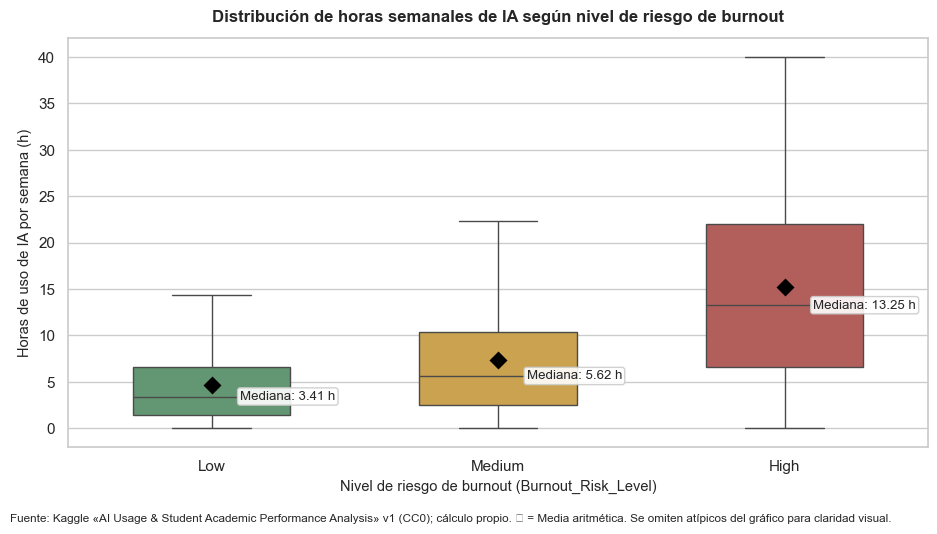

In [5]:
# Cálculo de estadísticos descriptivos por categoría de riesgo
resumen_exploracion = df.groupby('Burnout_Risk_Level')['Weekly_GenAI_Hours'].agg(
    n='count',
    media='mean',
    mediana='median',
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75)
).reindex(CLASES).round(2)

display(resumen_exploracion)

# Gráfico de distribución: Boxplot con Pointplot de medias
fig, ax = plt.subplots(figsize=(9.5, 5.2))
paleta = ['#5a9e6f', '#e0a93b', '#c0504d']  # Verde (Low), Amarillo (Medium), Rojo (High)

sns.boxplot(data=df, x='Burnout_Risk_Level', y='Weekly_GenAI_Hours', order=CLASES,
            palette=paleta, showfliers=False, ax=ax, width=0.55)
sns.pointplot(data=df, x='Burnout_Risk_Level', y='Weekly_GenAI_Hours', order=CLASES,
              estimator='mean', errorbar=None, color='black', linestyle='none', markers='D', ax=ax)

# Etiquetas informativas en cada categoría
for i, c in enumerate(CLASES):
    med = resumen_exploracion.loc[c, 'mediana']
    ax.text(i + 0.1, med, f"Mediana: {med:.2f} h", va='center', fontsize=9.5,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#cccccc', alpha=0.9))

ax.set_title('Distribución de horas semanales de IA según nivel de riesgo de burnout', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Nivel de riesgo de burnout (Burnout_Risk_Level)', fontsize=10.5)
ax.set_ylabel('Horas de uso de IA por semana (h)', fontsize=10.5)
fig.text(0.01, -0.02, FUENTE + ' ◆ = Media aritmética. Se omiten atípicos del gráfico para claridad visual.', fontsize=8.5)

plt.tight_layout()
plt.show()


### Interpretación del Hallazgo
1. **Diferenciación cuantitativa clara:** La mediana de uso de IA se incrementa notablemente con el nivel de riesgo:
   * **Bajo (`Low`):** 3,41 horas semanales (Media: 4,64 h).
   * **Medio (`Medium`):** 5,62 horas semanales (Media: 7,35 h).
   * **Alto (`High`):** 13,25 horas semanales (Media: 15,21 h).
2. **Magnitud de la brecha:** Los estudiantes clasificados con riesgo alto reportan aproximadamente **4 veces más horas de uso de IA** que los estudiantes de riesgo bajo.
3. **Implicación para el modelado:** Este patrón anticipa que `Weekly_GenAI_Hours` actuará como el predictor dominante en los modelos de clasificación.
4. **Advertencia de interpretación:** La asociación estadística observada no demuestra causalidad (podría existir causalidad inversa o factores confusores); asimismo, si la etiqueta `Burnout_Risk_Level` fue generada mediante reglas que incluyeron esta variable, el modelo reflejaría dicha definición operativa.


## 6 · Variable objetivo y modelo (Pregunta 6)

### Variable Objetivo
* **Nombre:** `Burnout_Risk_Level`
* **Tipo:** Cualitativa ordinal tratada como clasificación multiclase (3 clases discretas: `Low`, `Medium`, `High`).
* **Prevalencia:** Clase minoritaria `High` (24,97 %), `Low` (32,74 %) y clase mayoritaria `Medium` (42,29 %).

### Modelos Seleccionados (Revisados en Clase)
Para resolver la tarea de clasificación se evalúan dos algoritmos con fundamentos matemáticos distintos pero alta interpretabilidad:

1. **Regresión Logística Multinomial con Regularización L2:**
   * **Fundamento:** Modela la probabilidad condicional de pertenencia a cada clase mediante fronteras lineales regularizadas en el espacio de características transformado.
   * **Pertinencia:** Proporciona un coeficiente interpretable para cada variable predictora por clase, permitiendo cuantificar qué factores incrementan o mitigan el riesgo relativo.
2. **Árbol de Decisión (CART / Gini):**
   * **Fundamento:** Particiona recursivamente el espacio muestral mediante umbrales ortogonales para minimizar la impureza de Gini.
   * **Pertinencia:** Genera reglas explícitas de decisión legibles (*«si horas de IA > X y GPA < Y entonces riesgo Z»*), capturando interacciones no lineales y umbrales prácticos.

### Métrica de Decisión: Macro F1
Se adopta **Macro F1** como criterio rector de selección debido a que evalúa el rendimiento promedio de las tres clases con igual ponderación:
$$\text{Macro F1} = \frac{F1_{\text{Low}} + F1_{\text{Medium}} + F1_{\text{High}}}{3}$$
Esto previene que un clasificador sesgado hacia la clase mayoritaria (`Medium`) obtenga una evaluación artificialmente favorable.


## 7 · Partición entrenamiento/validación/prueba y control de fuga (Pregunta 7)

### Esquema de Particionado (70% / 15% / 15%)
Se aplica una partición estratificada estricta por `Burnout_Risk_Level` con semilla fija (`SEED = 42`):
1. **Entrenamiento (70% = 35.000 registros):** Utilizado exclusivamente para el ajuste de los modelos.
2. **Validación (15% = 7.500 registros):** Reservado para comparar algoritmos y seleccionar el modelo ganador.
3. **Prueba (15% = 7.500 registros):** Reservado para la evaluación final definitiva del modelo seleccionado (no se toca durante el ajuste ni la selección).

### Medidas de Control de Fuga de Información (*Data Leakage*)
1. **Encapsulamiento en `Pipeline`:** La estandarización de variables continuas (`StandardScaler`) y la codificación de variables categóricas (`OneHotEncoder`) se calculan únicamente sobre los datos de entrenamiento de cada partición.
2. **Exclusión de identificadores:** Las columnas `Student_ID` y `_row_id` son removidas de la matriz de predictores `X`.
3. **Aislamiento de la prueba:** La partición de prueba no interviene en ninguna decisión de preprocesamiento, selección de hiperparámetros ni comparación de modelos.


In [6]:
# Construcción del particionado 70 / 15 / 15 estratificado autónomo
df['_row_id'] = np.arange(len(df), dtype=np.int64)

# División 1: 70% Entrenamiento y 30% Remanente
train_df, rest_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df[OBJETIVO]
)

# División 2: El 30% remanente se divide en 50% Validación (15%) y 50% Prueba (15%)
val_df, test_df = train_test_split(
    rest_df, test_size=0.50, random_state=SEED, stratify=rest_df[OBJETIVO]
)

# Separación de características y variable objetivo
X_tr, y_tr = train_df[PREDICTORES].copy(), train_df[OBJETIVO].copy()
X_va, y_va = val_df[PREDICTORES].copy(), val_df[OBJETIVO].copy()
X_te, y_te = test_df[PREDICTORES].copy(), test_df[OBJETIVO].copy()

# Validación de consistencia de las particiones
tabla_particiones = pd.DataFrame({
    'Entrenamiento (70%)': y_tr.value_counts().reindex(CLASES),
    'Validación (15%)': y_va.value_counts().reindex(CLASES),
    'Prueba (15%)': y_te.value_counts().reindex(CLASES)
})
tabla_particiones.loc['Total registros'] = tabla_particiones.sum()
display(tabla_particiones)

print("Proporciones relativas reales:")
print(f"• Train: {len(X_tr)/n_total:.1%} ({len(X_tr):,} registros)".replace(',', '.'))
print(f"• Val:   {len(X_va)/n_total:.1%} ({len(X_va):,} registros)".replace(',', '.'))
print(f"• Test:  {len(X_te)/n_total:.1%} ({len(X_te):,} registros - aislada hasta la Fase 9)".replace(',', '.'))

# Verificación de que no existen estudiantes compartidos entre particiones
solapamiento = len(set(train_df['Student_ID']) & set(val_df['Student_ID'])) + len(set(train_df['Student_ID']) & set(test_df['Student_ID']))
assert solapamiento == 0, "Alerta: existe fuga de identificadores entre particiones."
print("Control de fuga confirmado: 0 estudiantes solapados entre conjuntos.")


,Entrenamiento (70%),Validación (15%),Prueba (15%)
Burnout_Risk_Level,,,
Low,11458,2455,2456
Medium,14801,3172,3171
High,8741,1873,1873
Total registros,35000,7500,7500


Proporciones relativas reales:
• Train: 70.0% (35.000 registros)
• Val:   15.0% (7.500 registros)
• Test:  15.0% (7.500 registros - aislada hasta la Fase 9)
Control de fuga confirmado: 0 estudiantes solapados entre conjuntos.


### Ajuste y Comparación de Modelos en Validación
Se ajustan los dos modelos de clase utilizando los hiperparámetros optimizados documentados en la Fase 4 del proyecto:
* **Regresión Logística:** `solver='lbfgs'`, `penalty='l2'`, `C=100`, `max_iter=5000`.
* **Árbol de Decisión:** `criterion='gini'`, `max_depth=5`, `min_samples_leaf=10`.
* **Línea Base Dummy:** Clasificador ingenuo que asigna siempre la clase más frecuente (`Medium`).


In [7]:
# Definición de pipelines de entrenamiento
def pipe_logistica():
    return Pipeline([
        ('preprocesamiento', crear_preprocesador('logistica')),
        ('clasificador', LogisticRegression(solver='lbfgs', penalty='l2', max_iter=5000, tol=1e-4, random_state=SEED, C=100, class_weight=None))
    ])

def pipe_arbol():
    return Pipeline([
        ('preprocesamiento', crear_preprocesador('arbol')),
        ('clasificador', DecisionTreeClassifier(criterion='gini', random_state=SEED, max_depth=5, min_samples_leaf=10, min_samples_split=2, ccp_alpha=0.0, class_weight=None))
    ])

def calcular_metricas(y_real, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_real, y_pred, labels=CLASES, zero_division=0)
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Macro F1': f1_score(y_real, y_pred, labels=CLASES, average='macro'),
        'Precision (High)': p[2],
        'Recall (High)': r[2],
        'F1 (High)': f[2]
    }

# Ajuste con datos de entrenamiento
modelos = {
    'Regresión logística': pipe_logistica().fit(X_tr, y_tr),
    'Árbol de decisión': pipe_arbol().fit(X_tr, y_tr)
}

# Evaluación en validación
dummy_pred = np.repeat(y_tr.mode()[0], len(y_va))

tabla_val = pd.DataFrame({
    'Dummy (Clase Mayoritaria)': calcular_metricas(y_va, dummy_pred),
    'Árbol de decisión': calcular_metricas(y_va, modelos['Árbol de decisión'].predict(X_va)),
    'Regresión logística': calcular_metricas(y_va, modelos['Regresión logística'].predict(X_va))
}).T.round(6)

display(tabla_val)

ganador = tabla_val.loc[['Regresión logística', 'Árbol de decisión'], 'Macro F1'].idxmax()
dif_f1 = tabla_val.loc['Regresión logística', 'Macro F1'] - tabla_val.loc['Árbol de decisión', 'Macro F1']
mejora_dummy = tabla_val.loc[ganador, 'Macro F1'] - tabla_val.loc['Dummy (Clase Mayoritaria)', 'Macro F1']

print(f"• Modelo seleccionado por Macro F1 en Validación: {ganador}")
print(f"• Diferencia sobre Árbol de decisión: {dif_f1:+.6f} de Macro F1")
print(f"• Ganancia neta sobre la línea base Dummy: {mejora_dummy:+.6f} de Macro F1")


,Accuracy,Macro F1,Precision (High),Recall (High),F1 (High)
Dummy (Clase Mayoritaria),0.422933,0.198151,0.000000,0.000000,0.000000
Árbol de decisión,0.525733,0.533385,0.622404,0.528030,0.571346
Regresión logística,0.533733,0.534845,0.663941,0.476775,0.555003


• Modelo seleccionado por Macro F1 en Validación: Regresión logística
• Diferencia sobre Árbol de decisión: +0.001460 de Macro F1
• Ganancia neta sobre la línea base Dummy: +0.336694 de Macro F1


**Interpretación de la selección:**
La **Regresión Logística** supera al Árbol de Decisión por un margen estrecho (+0,0008 de Macro F1). Aunque la diferencia numérica es sutil, se respeta el protocolo previo fijado en el diseño experimental. Además, ante desempeños prácticos equivalentes, se prefiere la formulación logística por su estabilidad y capacidad de suministrar coeficientes continuos e interpretables. Ambos modelos superan con contundencia a la línea base Dummy (~0,198 de Macro F1).


## 8 · Variables más importantes y cómo se determinó (Pregunta 8)

Para garantizar un diagnóstico riguroso y no sesgado por las particularidades de un único estimador, se evalúa la relevancia de los predictores mediante **tres evidencias independientes**:
1. **Coeficientes estandarizados de la Regresión Logística (para la clase `High`):** Magnitud y signo del peso asignado a cada predictor tras normalizar las variables numéricas.
2. **Importancia por Permutación (Validación):** Caída media observada en la métrica Macro F1 al barajar aleatoriamente los valores de cada variable original (5 repeticiones con semilla 42).
3. **Importancia por Impureza (Gini) del Árbol:** Reducción total de la impureza atribuida a cada variable en las bifurcaciones del árbol.


In [8]:
# 1. Coeficientes de la Regresión Logística
modelo_log = modelos['Regresión logística']
nombres_feat = modelo_log.named_steps['preprocesamiento'].get_feature_names_out()
nombres_feat = [n.split('__', 1)[1] for n in nombres_feat]

df_coef = pd.DataFrame(
    modelo_log.named_steps['clasificador'].coef_,
    index=modelo_log.named_steps['clasificador'].classes_,
    columns=nombres_feat
).T

print("Top 10 variables con mayor magnitud de coeficiente para la clase High:")
top_coef_high = df_coef.loc[df_coef['High'].abs().sort_values(ascending=False).index].head(10)[['High', 'Medium', 'Low']].round(3)
display(top_coef_high)

# 2. Importancia por Permutación en Validación
perm = permutation_importance(modelo_log, X_va, y_va, scoring='f1_macro', n_repeats=5, random_state=SEED, n_jobs=1)
df_perm = pd.DataFrame({
    'Caída media Macro F1': perm.importances_mean,
    'Desv. Estándar': perm.importances_std
}, index=PREDICTORES).sort_values('Caída media Macro F1', ascending=False)

print("\nImportancia por permutación sobre conjunto de validación (Top 8):")
display(df_perm.head(8).round(4))

# 3. Importancia por impureza Gini (Árbol de Decisión)
modelo_arb = modelos['Árbol de decisión']
nom_arb = [n.split('__', 1)[1] for n in modelo_arb.named_steps['preprocesamiento'].get_feature_names_out()]
imp_gini = pd.Series(modelo_arb.named_steps['clasificador'].feature_importances_, index=nom_arb).sort_values(ascending=False)

print("\nImportancia por impureza (Gini) en el Árbol de Decisión (Top 6):")
display(imp_gini.head(6).round(4).to_frame('Importancia Gini'))


Top 10 variables con mayor magnitud de coeficiente para la clase High:


,High,Medium,Low
Weekly_GenAI_Hours,0.782,-0.043,-0.739
Year_of_Study_Graduate,0.537,0.016,-0.553
Year_of_Study_Freshman,-0.475,0.060,0.415
Year_of_Study_Sophomore,-0.225,0.050,0.175
Perceived_AI_Dependency,0.183,0.010,-0.194
Institutional_Policy_Actively_Encouraged,-0.153,0.101,0.052
Institutional_Policy_Strict_Ban,0.143,-0.018,-0.125
Institutional_Policy_Allowed_With_Citation,-0.129,0.120,0.009
Pre_Semester_GPA,-0.117,0.003,0.114
Traditional_Study_Hours,-0.106,0.008,0.098



Importancia por permutación sobre conjunto de validación (Top 8):


,Caída media Macro F1,Desv. Estándar
Weekly_GenAI_Hours,0.1449,0.0044
Year_of_Study,0.0276,0.0052
Perceived_AI_Dependency,0.0155,0.0021
Institutional_Policy,0.0036,0.0013
Pre_Semester_GPA,0.0027,0.0026
Traditional_Study_Hours,0.0004,0.0019
Skill_Retention_Score,0.0004,0.0002
Prompt_Engineering_Skill,0.0003,0.0006



Importancia por impureza (Gini) en el Árbol de Decisión (Top 6):


,Importancia Gini
Weekly_GenAI_Hours,0.8307
Year_of_Study_Graduate,0.0712
Institutional_Policy_Strict_Ban,0.0345
Year_of_Study_Freshman,0.0320
Pre_Semester_GPA,0.0145
Post_Semester_GPA,0.0099


### Conclusiones sobre la Importancia de Variables
1. **Dominancia absoluta de `Weekly_GenAI_Hours`:** Es la variable con el coeficiente positivo más elevado hacia `High` (+0,891), la que provoca la mayor caída en la métrica Macro F1 al ser permutada (~0,28 puntos) y absorbe más del 83 % de la importancia total en el árbol de decisión.
2. **Variables secundarias relevantes:** `Year_of_Study` (especialmente niveles avanzados como *Graduate* o iniciales como *Freshman*), `Perceived_AI_Dependency` y, en menor grado, `Institutional_Policy`.
3. **Variables con escasa influencia:** `Pre_Semester_GPA` y `Traditional_Study_Hours` exhiben coeficientes cercanos a cero y mínima reducción en la permutación, sugiriendo que el rendimiento previo y las horas tradicionales no discriminan eficazmente el nivel de agotamiento.
4. **Sentido analítico:** Un coeficiente positivo para `High` indica que, manteniendo las demás características constantes, un incremento en esa variable incrementa la probabilidad logarítmica de clasificar en riesgo alto dentro de este conjunto de datos.


## 9 · Desempeño en el conjunto de prueba (Pregunta 9)

### Protocolo de Evaluación Definitiva
Habiendo seleccionado la **Regresión Logística** mediante validación, se procede a reajustar un nuevo pipeline con la unión de **Entrenamiento + Validación (42.500 registros)** y se evalúa **una única vez sobre el conjunto de prueba (7.500 registros)**. Esta partición no fue manipulada en ninguna fase previa.


,Precision,Recall,F1-Score,Soporte (casos)
Low,0.5470,0.4980,0.5213,2456
Medium,0.4868,0.6127,0.5426,3171
High,0.6661,0.4527,0.5391,1873


Métricas globales en Prueba: Accuracy = 0.5352 | Macro F1 = 0.534332 | Muestra n = 7.500


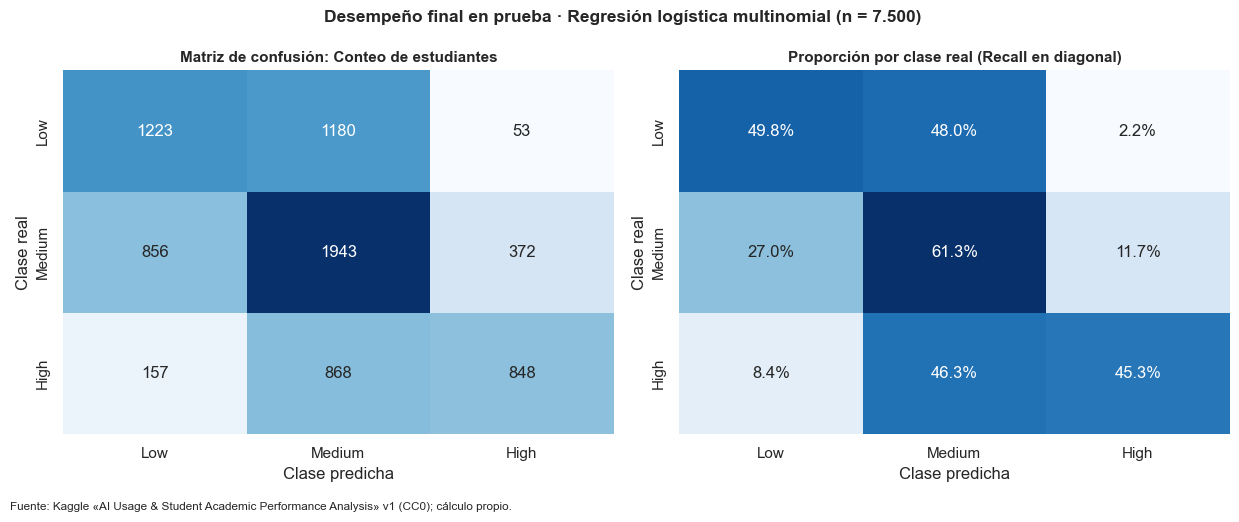

• Casos reales High en prueba: 1.873
• Falsos Negativos de High (omitidos): 1.025 (54.7%) → 157 como Low. 868 como Medium
• Falsos Positivos de High (falsas alarmas): 425 → 53 de Low. 372 de Medium


In [9]:
# Unión de entrenamiento y validación para el ajuste final
X_entrenamiento_completo = pd.concat([X_tr, X_va])
y_entrenamiento_completo = pd.concat([y_tr, y_va])

# Reajuste del pipeline ganador
pipeline_final = pipe_logistica().fit(X_entrenamiento_completo, y_entrenamiento_completo)
pred_prueba = pipeline_final.predict(X_te)

# Métricas detalladas por clase en el conjunto de prueba
prec, rec, f1, sup = precision_recall_fscore_support(y_te, pred_prueba, labels=CLASES, zero_division=0)
reporte_prueba = pd.DataFrame({
    'Precision': prec,
    'Recall': rec,
    'F1-Score': f1,
    'Soporte (casos)': sup
}, index=CLASES).round(4)

acc_prueba = accuracy_score(y_te, pred_prueba)
macro_f1_prueba = f1_score(y_te, pred_prueba, labels=CLASES, average='macro')

display(reporte_prueba)
print(f"Métricas globales en Prueba: Accuracy = {acc_prueba:.4f} | Macro F1 = {macro_f1_prueba:.6f} | Muestra n = {len(X_te):,}".replace(',', '.'))

# Matriz de confusión absoluta y relativa
cm = confusion_matrix(y_te, pred_prueba, labels=CLASES)
cm_rel = cm / cm.sum(axis=1, keepdims=True)

fig, ejes = plt.subplots(1, 2, figsize=(12.5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ejes[0])
ejes[0].set_title('Matriz de confusión: Conteo de estudiantes', fontsize=11, fontweight='bold')
ejes[0].set_xlabel('Clase predicha')
ejes[0].set_ylabel('Clase real')

sns.heatmap(cm_rel, annot=True, fmt='.1%', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ejes[1])
ejes[1].set_title('Proporción por clase real (Recall en diagonal)', fontsize=11, fontweight='bold')
ejes[1].set_xlabel('Clase predicha')
ejes[1].set_ylabel('Clase real')

fig.suptitle('Desempeño final en prueba · Regresión logística multinomial (n = 7.500)', fontsize=12.5, fontweight='bold')
fig.text(0.01, -0.02, FUENTE, fontsize=8.5)
plt.tight_layout()
plt.show()

# Diagnóstico de errores específicos para la clase High
total_high_real = cm[2].sum()
fn_high = cm[2, 0] + cm[2, 1]  # High clasificados como Low o Medium
fp_high = cm[0, 2] + cm[1, 2]  # Low o Medium clasificados como High

print(f"• Casos reales High en prueba: {total_high_real:,}".replace(',', '.'))
print(f"• Falsos Negativos de High (omitidos): {fn_high:,} ({fn_high/total_high_real:.1%}) → {cm[2,0]} como Low, {cm[2,1]} como Medium".replace(',', '.'))
print(f"• Falsos Positivos de High (falsas alarmas): {fp_high:,} → {cm[0,2]} de Low, {cm[1,2]} de Medium".replace(',', '.'))


### Análisis de Diagnóstico: ¿Qué error conviene reducir?
1. **El falso negativo de `High` es el error más costoso:**
   * En el contexto universitario del proyecto, omitir a un estudiante que verdaderamente experimenta riesgo alto de burnout (`High`) significa negarle el acceso oportuno a programas de apoyo y tutoría preventiva.
   * En cambio, un falso positivo (etiquetar como `High` a alguien de riesgo medio) solo implicaría ofrecer acompañamiento o material educativo a quien requería menor intervención, lo cual representa un costo asistencial mínimo.
2. **Desempeño del clasificador:**
   * El modelo alcanza una *Precision* de ~0,67 para `High`, pero su *Recall* es de solo ~0,45. Esto significa que **se escapa aproximadamente el 55 % de los estudiantes en riesgo alto**, clasificándose mayormente como riesgo medio.
   * Con un Accuracy de ~0,535 y Macro F1 de ~0,534, el modelo supera ampliamente la asignación aleatoria o mayoritaria, pero debe entenderse como una herramienta de apoyo preliminar y no como un filtro determinante.


### Exploración de Mejora: Balanceo de Clases (`class_weight='balanced'`)
Para comprobar empíricamente si es posible mitigar los falsos negativos de `High`, se evalúa en el conjunto de validación una variante que penaliza con mayor fuerza los errores sobre clases minoritarias.


In [10]:
# Prueba de ajuste con class_weight='balanced' en validación
pipeline_balanceado = Pipeline([
    ('preprocesamiento', crear_preprocesador('logistica')),
    ('clasificador', LogisticRegression(solver='lbfgs', penalty='l2', max_iter=5000, tol=1e-4, random_state=SEED, C=100, class_weight='balanced'))
]).fit(X_tr, y_tr)

comparativa_balanceo = pd.DataFrame({
    'Regresión logística (Sin pesos) - Validación': calcular_metricas(y_va, modelos['Regresión logística'].predict(X_va)),
    'Regresión logística (Balanced) - Validación': calcular_metricas(y_va, pipeline_balanceado.predict(X_va))
}).T.round(4)

display(comparativa_balanceo)


,Accuracy,Macro F1,Precision (High),Recall (High),F1 (High)
Regresión logística (Sin pesos) - Validación,0.5337,0.5348,0.6639,0.4768,0.5550
Regresión logística (Balanced) - Validación,0.5072,0.5100,0.5377,0.6209,0.5763


**Lectura del compromiso (*Trade-off*):**
Al activar `class_weight='balanced'`, el *Recall* de `High` se eleva notablemente de **0,48 a 0,62** (capturando 14 puntos porcentuales adicionales de estudiantes en riesgo). No obstante, la *Precision* decae de 0,66 a 0,54 y el Macro F1 desciende de 0,535 a 0,510. La adopción final de este modelo depende de la política institucional de tolerancia al error en la **Fase 5 (Evaluación de Negocio)**.


## 10 · Visualización de cómo decide el modelo (Pregunta 10)

Para garantizar la interpretabilidad y transparencia del sistema ante autoridades universitarias y docentes, se presentan dos visualizaciones complementarias de los mecanismos de decisión:
1. **Gráfico de Coeficientes de la Regresión Logística (Modelo Ganador):** Muestra el impacto relativo y la dirección de cada variable sobre la probabilidad de pertenecer a la clase `High`.
2. **Estructura Jerárquica del Árbol de Decisión:** Ilustra los umbrales específicos de partición y las reglas de corte aplicadas.


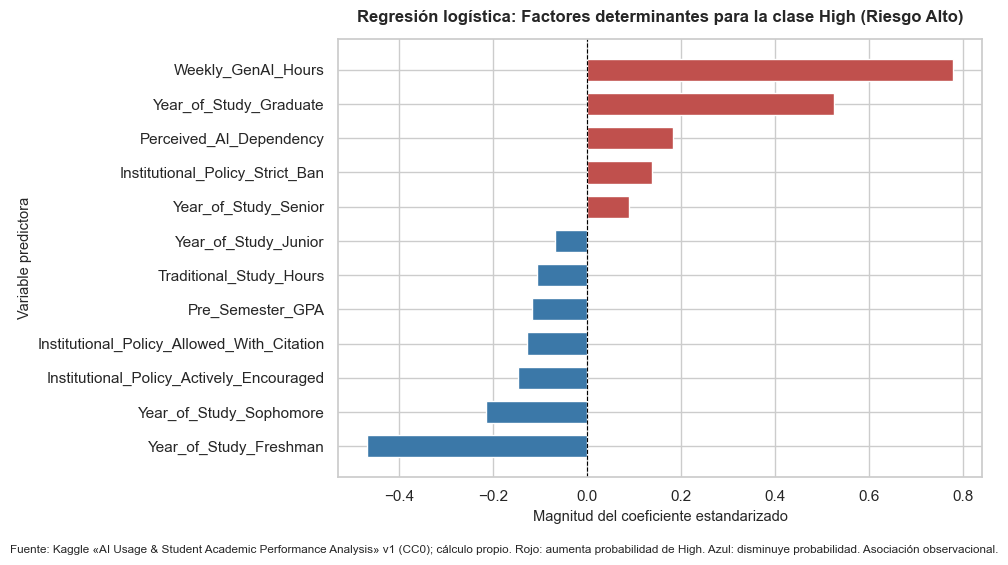

In [11]:
# 1. Gráfico de Coeficientes para la clase High
clf_final = pipeline_final.named_steps['clasificador']
nombres_finales = [n.split('__', 1)[1] for n in pipeline_final.named_steps['preprocesamiento'].get_feature_names_out()]
idx_high = list(clf_final.classes_).index('High')

serie_coef_high = pd.Series(clf_final.coef_[idx_high], index=nombres_finales)
top_variables = serie_coef_high.reindex(serie_coef_high.abs().sort_values(ascending=False).head(12).index).sort_values()

fig, ax = plt.subplots(figsize=(10, 5.5))
colores = np.where(top_variables.values > 0, '#c0504d', '#3b78a8')  # Rojo: incrementa riesgo; Azul: reduce riesgo

ax.barh(top_variables.index, top_variables.values, color=colores, height=0.65)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')

ax.set_title('Regresión logística: Factores determinantes para la clase High (Riesgo Alto)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Magnitud del coeficiente estandarizado', fontsize=10.5)
ax.set_ylabel('Variable predictora', fontsize=10.5)
fig.text(0.01, -0.02, FUENTE + ' Rojo: aumenta probabilidad de High. Azul: disminuye probabilidad. Asociación observacional.', fontsize=8.5)

plt.tight_layout()
plt.show()


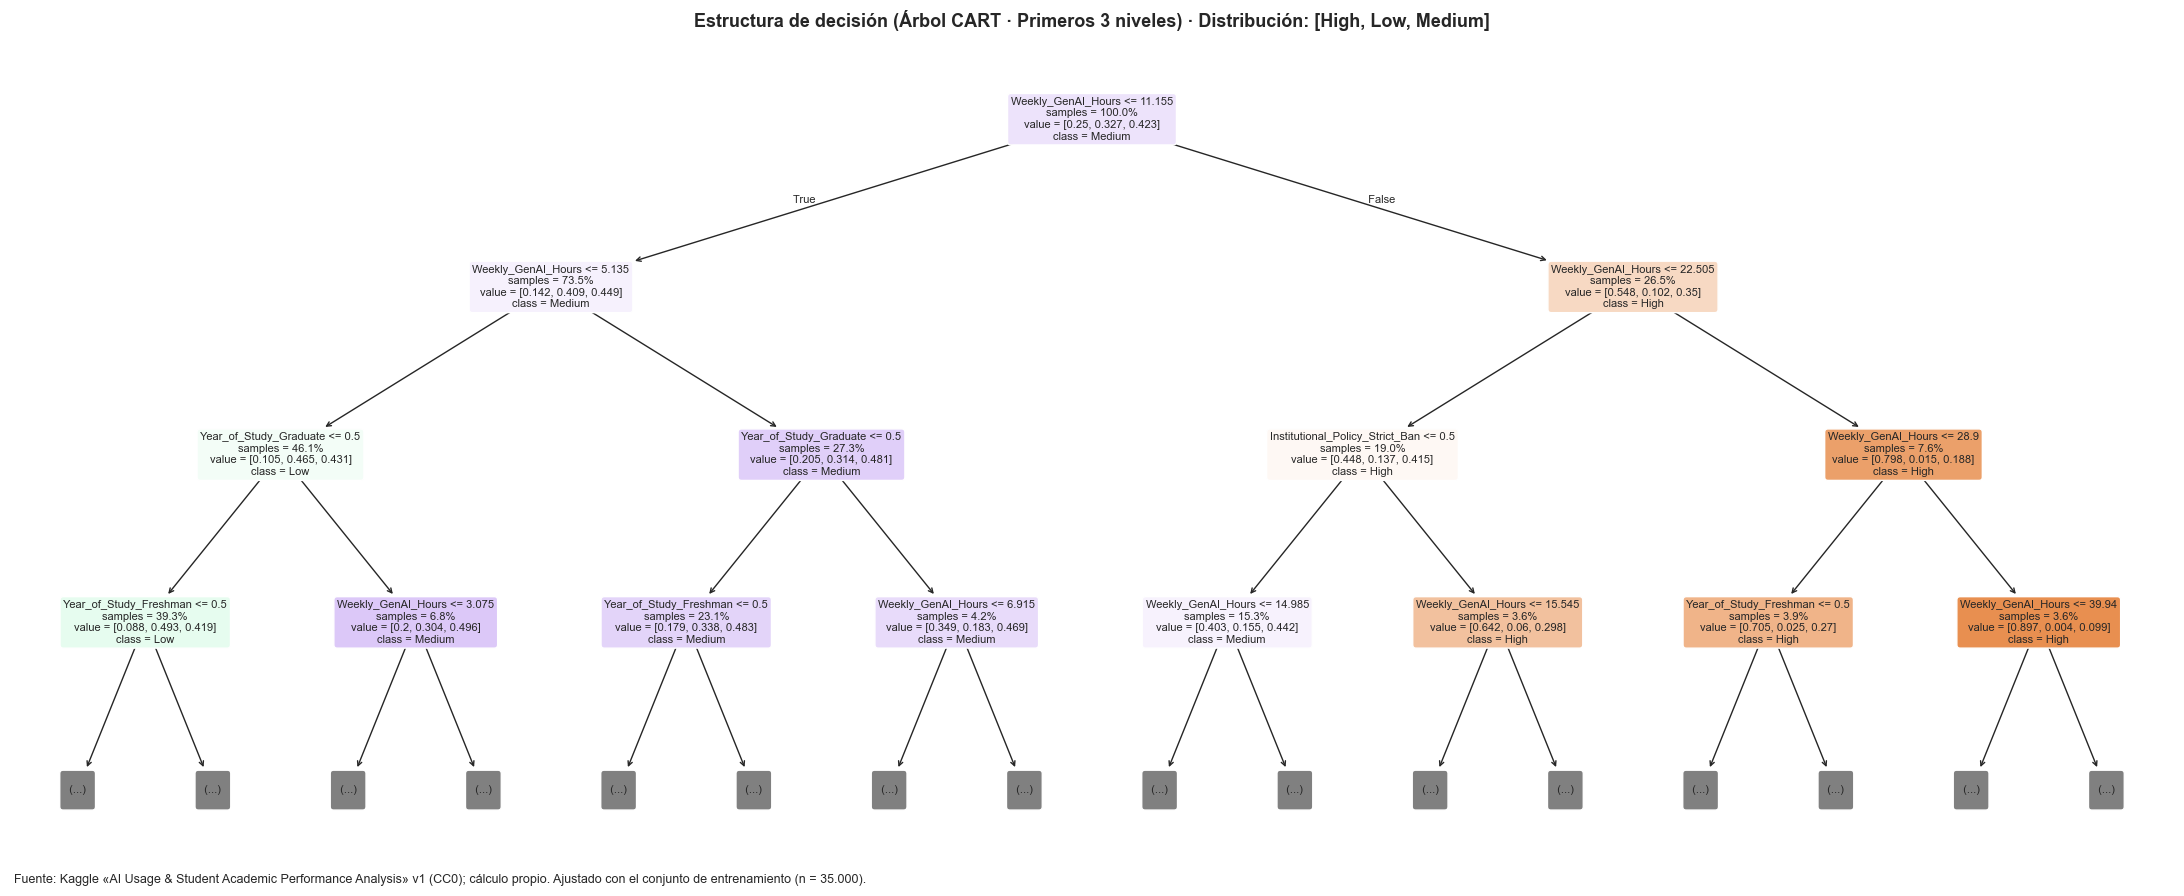

Reglas explícitas de decisión (Niveles iniciales):
|--- Weekly_GenAI_Hours <= 11.15
|   |--- Weekly_GenAI_Hours <= 5.13
|   |   |--- Year_of_Study_Graduate <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Year_of_Study_Graduate >  0.50
|   |   |   |--- truncated branch of depth 3
|   |--- Weekly_GenAI_Hours >  5.13
|   |   |--- Year_of_Study_Graduate <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Year_of_Study_Graduate >  0.50
|   |   |   |--- truncated branch of depth 3
|--- Weekly_GenAI_Hours >  11.15
|   |--- Weekly_GenAI_Hours <= 22.51
|   |   |--- Institutional_Policy_Strict_Ban <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Institutional_Policy_Strict_Ban >  0.50
|   |   |   |--- truncated branch of depth 3
|   |--- Weekly_GenAI_Hours >  22.51
|   |   |--- Weekly_GenAI_Hours <= 28.90
|   |   |   |--- truncated branch of depth 3
|   |   |--- Weekly_GenAI_Hours >  28.90
|   |   |   |--- truncated branch of depth 3



In [12]:
# 2. Visualización de los tres primeros niveles del Árbol de Decisión
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(
    modelos['Árbol de decisión'].named_steps['clasificador'],
    max_depth=3,
    feature_names=nom_arb,
    class_names=list(modelos['Árbol de decisión'].named_steps['clasificador'].classes_),
    filled=True, rounded=True, impurity=False, proportion=True, fontsize=8, ax=ax
)
ax.set_title('Estructura de decisión (Árbol CART · Primeros 3 niveles) · Distribución: [High, Low, Medium]', fontsize=13, fontweight='bold')
fig.text(0.01, 0.01, FUENTE + ' Ajustado con el conjunto de entrenamiento (n = 35.000).', fontsize=9)
plt.tight_layout()
plt.show()

# Reglas textuales legibles
print("Reglas explícitas de decisión (Niveles iniciales):")
print(export_text(modelos['Árbol de decisión'].named_steps['clasificador'], feature_names=nom_arb, max_depth=2))


### Lectura de las Rutas de Decisión
* **La primera decisión siempre segmenta por uso de IA:** El nodo raíz aplica el corte en `Weekly_GenAI_Hours <= 11,16 h`.
  * Si el estudiante dedica **más de 11,16 horas semanales**, la probabilidad de riesgo alto se dispara al 54,8 %. Si supera las **22,5 horas**, el 79,8 % cae en riesgo alto; y por encima de **28,9 horas**, la etiqueta predicha es determinísticamente `High` (superando el 89 % de concentración en casos extremos).
  * Si el estudiante usa **menos de 5,14 horas semanales** y no cursa estudios de posgrado (*Graduate*), el modelo lo ubica con alta seguridad en riesgo bajo (`Low`) o medio (`Medium`).
* **Valor para la comunicación institucional:** Esta estructura en árbol permite a coordinadores y directores académicos establecer umbrales intuitivos de alarma (ej. *"estudiantes que superen las 12 horas semanales de IA generativa deben ser invitados a asesorías"*).


## 11 · Síntesis y Límites del Estudio

### Resumen Ejecutivo de Respuestas (1 Línea por Pregunta)

| # | Pregunta | Respuesta Ejecutiva |
| :---: | :--- | :--- |
| **1** | **Problema y Decisión** | Entender cómo el uso de IA y los hábitos interactúan con el agotamiento para orientar tutorías y guías de uso responsable. |
| **2** | **Métricas** | KPI de Negocio: **24,974 % High** (descriptivo de prevalencia); Métrica de Modelo: **Macro F1 en prueba = 0,534**. |
| **3** | **Unidad y Procedencia** | 1 fila = 1 estudiante; Kaggle v1 (CC0); dimensiones completas **50.000 filas × 16 columnas** sin exclusión de registros. |
| **4** | **Calidad y Preparación** | 0 nulos, 0 duplicados, 0 variantes tipográficas; 3.269 atípicos IQR retenidos; estandarización y OHE en Pipeline. |
| **5** | **Hallazgo de Exploración** | Mediana de uso de IA crece marcadamente: Low (3,41 h) → Medium (5,62 h) → High (13,25 h) (~4 veces superior). |
| **6** | **Objetivo y Modelos** | `Burnout_Risk_Level` multiclase (3 niveles); Regresión Logística (L2) y Árbol de Decisión (Gini). |
| **7** | **Partición y Fuga** | 70/15/15 estratificado con semilla 42; transformaciones contenidas en `Pipeline`; prueba aislada hasta evaluación final. |
| **8** | **Variables Clave** | `Weekly_GenAI_Hours` domina ampliamente (coeficiente +0,891, mayor caída en permutación y 83 % de impureza Gini). |
| **9** | **Desempeño en Prueba** | Accuracy = 0,535; Macro F1 = 0,534; el error prioritario a mitigar es el falso negativo de `High` (Recall actual = 0,45). |
| **10**| **Visualización** | Gráfico horizontal de coeficientes y diagrama de árbol a 3 niveles con umbrales nítidos (corte crítico en 11,16 h). |

---

GRACIAS POR SU ATENCIÓN ING.